# 01 · Data Exploration and Preparation

**Name:** Mukunzi Ndahiro James  
**Course:** Machine Learning Techniques I  
**Assignment:** Summative Project: Domain-Specific Question Answering (AfriMed Assistant)

In this notebook I study the AfriMed-QA v2 dataset before training anything. My goal is to understand what kinds of questions it contains, how many of them have usable reference answers, and what quality problems it has. At the end I build the train, validation and test splits that every later notebook uses.

I chose AfriMed-QA because it is real data written by African clinicians, medical students and members of the public across many countries and specialties, which matches my goal of a medical assistant for African healthcare settings.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os
os.environ.setdefault("AFRIMED_ROOT", str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

Here I set up the paths and import my own package `afrimed` from `src/`. All the data logic lives in `src/afrimed/data.py`, so the notebook only calls functions and shows results.

Next I load the raw data. The dataset is gated on Hugging Face, so I use my access token. The first time, it downloads and caches a parquet file in `data/raw/`; after that it loads from disk.

In [2]:
from afrimed.data import load_raw, build_records, prepare
from afrimed import plots

raw = load_raw()
print(raw.shape)
raw.head(3)

(15275, 29)


,sample_id,split,gender,discipline,clinical_experience,country,question_type,prompt,question,question_clean,...,neg_percent,quality,rated_african,rated_correct,rated_omission,rated_hallucination,rated_reasonable,rated_harmful,rated_bias,version
0,ff784abc6b461a6a15d7f8bf5e6560d3393474fe4748699ff4c7f2124292b95f,train,Male,Non-Health,Intern,NG,consumer_queries,"Your female friend complains of weight gain, high blood pressure and thinks she has Lupus Nephritis and is going to ...",Can you provide recommendations for managing stress and improving mental well-being in relation to my condition?,Can you provide recommendations for managing stress and improving mental well-being in relation to my condition?,...,0.0,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v3
1,acc9497c6ed60ef124601649d5147899d7f621d8bcc1c28178a5aca923c9f7eb,test,Male,NaN,NaN,NG,consumer_queries,"Your female coworker complains of lump in breast, changes in skin and thinks she has Breast Cancer and is going to v...",What are the signs of breast cancer?,What are the signs of breast cancer?,...,1.0,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v3
2,ba40a9d3265c21e5350ce753ea7f9a37b8e27dfe5dc6082010e8cb3fc07d2ed0,test,Female,Other Health Professions,Intern,NG,consumer_queries,"Your female friend complains of bleeding, neck pain and thinks she has Crimean-Congo Hemorrhagic Fever and is going ...",What do you mean by saying Crimean Congo Hemorrhagic fever?How does this fever affect my level of productivity?,What do you mean by saying Crimean Congo Hemorrhagic fever?How does this fever affect my level of productivity?,...,0.0,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v3


## 1. Raw schema and missing values

In [3]:
missing = raw.replace({"None": None, "nan": None}).isna().mean().sort_values(ascending=False)
display(missing.to_frame("missing_fraction").T.round(3))
raw.question_type.value_counts().to_frame("rows")

,rated_omission,rated_bias,rated_correct,rated_harmful,rated_reasonable,rated_hallucination,answer_rationale,quality,answer_options,correct_answer,...,sample_id,neg_percent,tier,split,question_clean,question,question_type,country,gender,version
missing_fraction,0.996,0.996,0.996,0.996,0.996,0.996,0.888,0.802,0.736,0.736,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,rows
question_type,
consumer_queries,10000
mcq,4039
saq,1236


The raw table has 15,275 rows and 29 columns. The reviewer rating columns (`rated_correct`, `rated_harmful`, and so on) are 99.6% empty, so I cannot use them as labels. `answer_options` and `correct_answer` are only filled for MCQs, which is expected.

The three question types are very unbalanced: 10,000 consumer queries, 4,039 MCQs and 1,236 SAQs. This already tells me that the consumer queries, although they are the majority, may not be the most useful part for supervised training.

In [4]:
rec = build_records(raw)
rec[["question_type", "official_split", "question", "context", "options", "answer_letters", "rationale", "specialty", "tier"]].sample(6, random_state=1)

,question_type,official_split,question,context,options,answer_letters,rationale,specialty,tier
9201,consumer_queries,train,"What potential lifestyle factors or habits could be exacerbating my Cardiomyopathy symptoms?""","A patient has shortness of breath, swelling and suspects Cardiomyopathies.",[],,,Cardiology,crowdsourced
4244,consumer_queries,train,Which type of work or exercise can cause rheumatic heart disease?,"A child has chest pain, fatigue and suspects Rheumatic Heart Disease.",[],,,Unspecified,crowdsourced
14095,mcq,test,Polyhydramnios,,"[Refers to amniotic fluid above 95percentile, Is associated with anencephaly, Often complicate diabetes mellitus in ...","A,B,C",,Obstetrics_and_Gynecology,expert
1436,consumer_queries,train,Ask the doctor that what are the root cause of epilepsy and also the attributes of epilepsy. This question will help...,A patient has seizures and suspects Epilepsy.,[],,,Unspecified,crowdsourced
2958,consumer_queries,train,How does one fix a malnutrition,"A child has weight loss, stunted growth and suspects Malnutrition.",[],,,Unspecified,crowdsourced
813,consumer_queries,test,"""Are there any lifestyle habits or preventive measures I can take to reduce my risk of recurrent urinary tract infec...","A patient has painful urination, fever and suspects Urinary Tract Infections.",[],,,Unspecified,crowdsourced


I convert every raw row into one clean record with the same fields for all question types: the question, an optional scenario `context`, the answer options, the correct letters, the reference answer (`rationale`), the specialty and the tier (expert or crowdsourced). Having one format makes it easy to build prompts and to compute metrics later.

## 2. Question types and official split

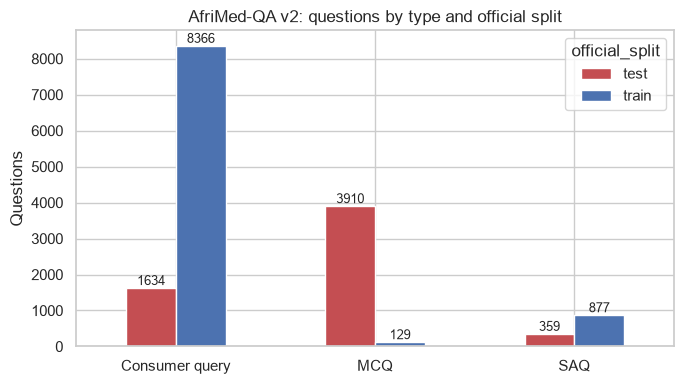

In [5]:
plots.plot_question_types(rec); plt.show()

The official split was designed for benchmarking language models, not for training them. Almost all expert MCQs are in the official test split, so if I used it directly my model would be trained on one kind of question and tested on another. Because of this I make my own split in section 6, stratified by question type and tier, so train, validation and test come from the same distribution.

## 3. Reference answer availability

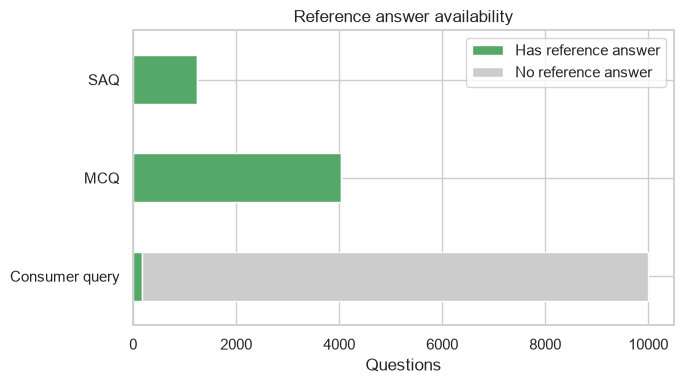

In [6]:
plots.plot_answer_availability(rec); plt.show()

In [7]:
ans = rec[(rec.question_type == "consumer_queries") & (rec.rationale_words > 0)]
print(ans.rationale_words.describe())
ans[["question", "rationale"]].sample(8, random_state=3)

count    169.000000
mean      15.633136
std        9.568442
min        1.000000
25%        5.000000
50%       17.000000
75%       23.000000
max       38.000000
Name: rationale_words, dtype: float64


,question,rationale
4196,What are the specific signs and symptoms of pre-eclampsia and eclampsia that I should watch out for at home?,"The key signs and symptoms to watch out for at home include blood pressure, persistent headache and vision changes."
5078,Could physical therapy help relieve my TMJ arthritis symptoms?,Yes
8584,"In addition to treating the rash itself, are there any recommendations to manage the itching at home, and can certai...","To manage itching at home, try cool compresses, moisturizers, and over-the-counter anti-itch creams. Avoid hot water..."
873,Is heartburn and chest pain also symptoms of ulcer?,"If you have heartburn, the pain is usually felt in the upper chest and throat. If you have ulcers, on the other hand..."
3368,Are the medications used to manage this condition easily accessible to an average individual?,"While some medications can be gotten over the counter and are easily accessible to any individual, some others can o..."
1239,"What are the available options for managing cancer pain, and how can we create a personalized pain management plan?",1. Anti-inflammatory drugs.2. Muscle relaxers. ...3. Scrambler therapy. ...4. Steroid injections. ...5. Neurolytic p...
5020,Will I be needing hearing Aids?,Yes you would need it since your hearing loss is of the conductive type
6767,"UTI, is it caused by multiple sexual partners?",Having multiple sexual partners increases the risk of UTIs especially in women. These multiple sexual partners great...


This is the biggest data problem I found. Only 169 of the 10,000 consumer queries have a reference answer. The answers that exist are short: the median is 17 words, and a quarter of them have 5 words or fewer (for example "They are many" or "The chances are minimal").

Because of this I train mainly on MCQs and SAQs, and I only keep consumer answers with at least 4 words. The thousands of unanswered consumer queries are still valuable: they are real questions from the public, so I use them as in-domain examples for the domain gate in notebook 02.

## 4. Specialties, countries and contributors

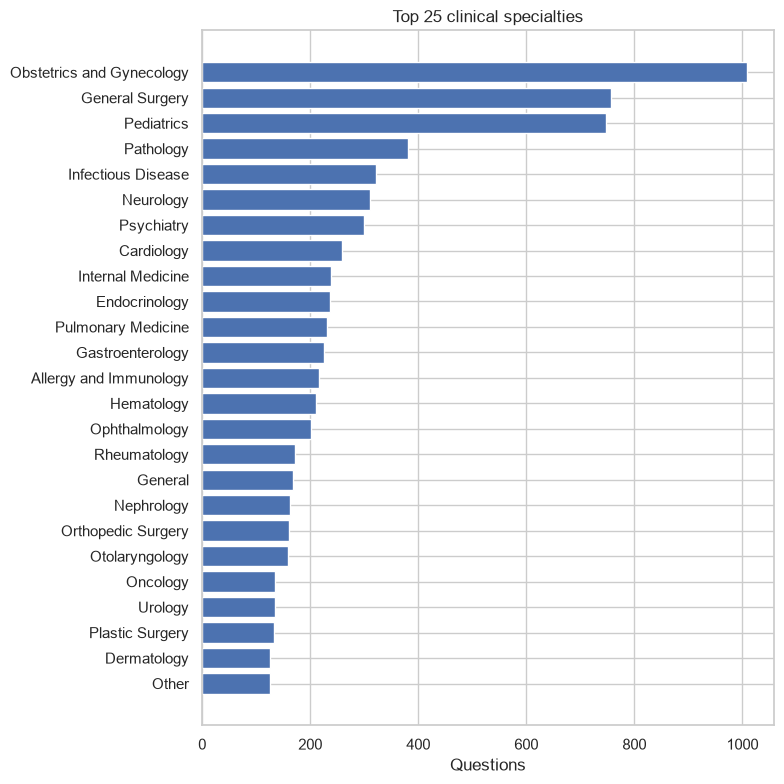

In [8]:
plots.plot_specialties(rec); plt.show()

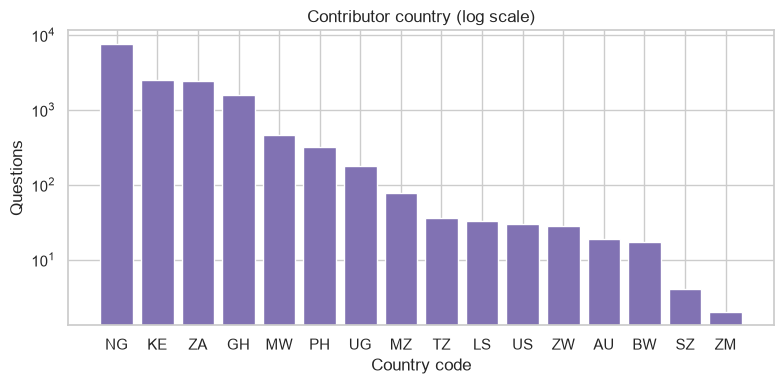

In [9]:
plots.plot_countries(rec); plt.show()

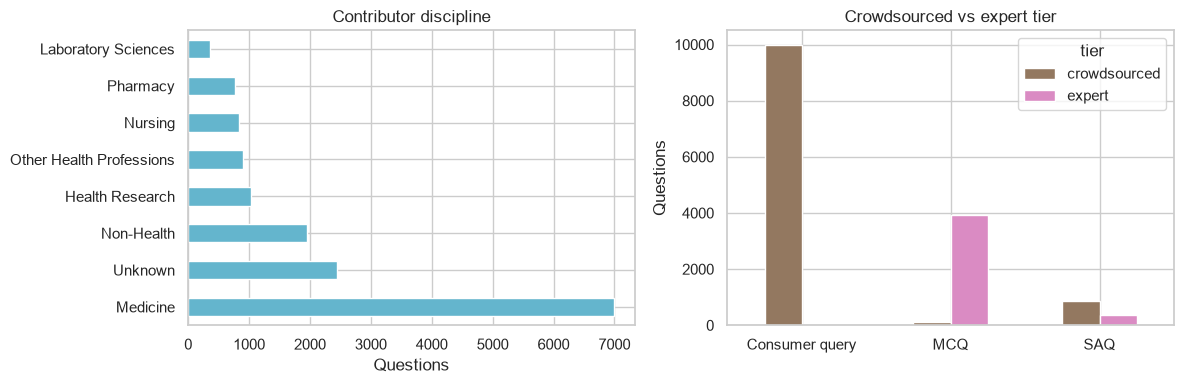

In [10]:
plots.plot_contributors(rec); plt.show()

Most questions come from Nigeria, Kenya, South Africa and Ghana, and the contributor plot shows how the data is spread over the people who wrote it. The largest specialties are Obstetrics and Gynecology, General Surgery and Pediatrics, which fits the disease burden the dataset authors targeted.

This imbalance matters for evaluation: specialties with only a handful of test questions will have noisy accuracy, and countries with few contributors are under-represented, so my model may work better for some settings than others.

## 5. Lengths, answer positions and quality

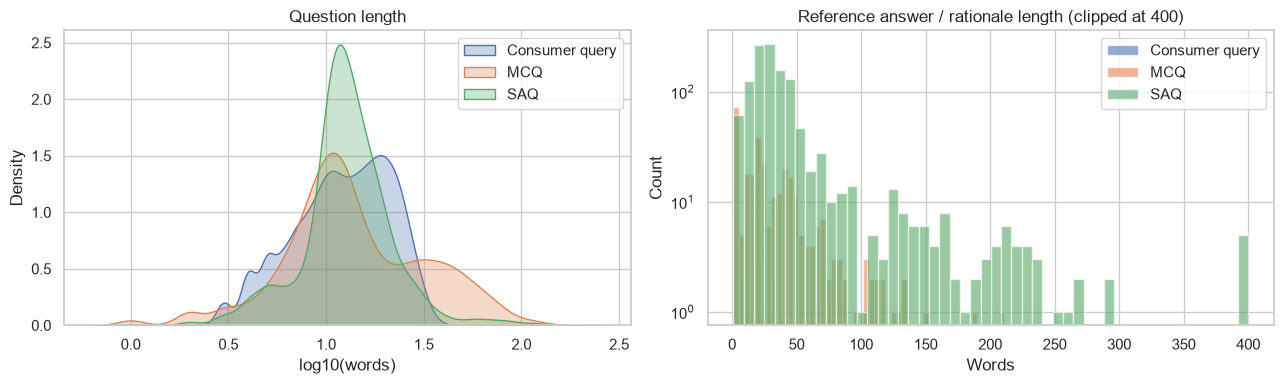

In [11]:
plots.plot_lengths(rec); plt.show()

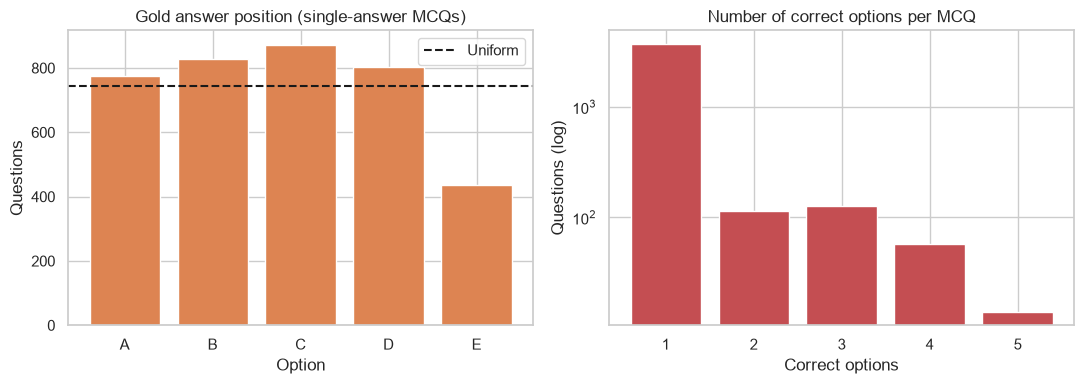

multi-answer MCQs: 312 (7.7%)
MCQs with a rationale: 304


In [12]:
_, sup, unlabeled, report = prepare()
plots.plot_mcq_answers(sup); plt.show()
mcq = sup[sup.question_type == "mcq"]
print("multi-answer MCQs:", int(mcq.multi_answer.sum()), f"({mcq.multi_answer.mean():.1%})")
print("MCQs with a rationale:", int((mcq.rationale_words > 0).sum()))

312 MCQs (7.7%) have more than one correct answer. These need a different metric than normal MCQs, so later I report exact match and Jaccard overlap for them separately.

The correct letters are also not spread evenly over A to E (E is the least common). A model could gain a few points just by learning this position pattern instead of medicine. To measure this, I add a majority-letter baseline in notebook 02 and check the predicted letter distribution in notebook 04.

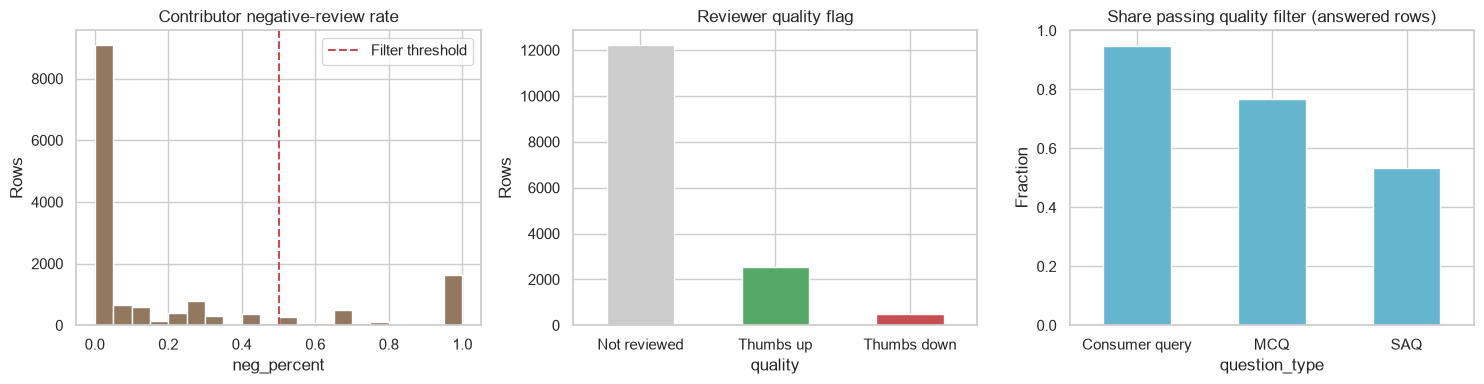

In [13]:
plots.plot_quality(rec); plt.show()

Each row has a `neg_percent`: the share of that contributor's answers that reviewers rated as bad. I mark a row as clean when it is not flagged by reviewers and `neg_percent` is at most 0.5. About 72% of my training rows are clean. I use this filter in the `lora_qwen05_r16_clean` experiment to test whether training only on higher-quality rows helps.

## 6. Preparation pipeline

My preparation pipeline (`afrimed.data.prepare()`) does the following steps in order:

1. **Text cleaning:** uses the cleaned question text and normalises whitespace.
2. **Scenario parsing:** turns long consumer templates ("Your female friend complains of X and thinks she has Y...") into a short context such as "A patient has X and suspects Y."
3. **De-duplication:** removes repeated questions.
4. **Answer filtering:** keeps only rows with a usable answer (correct letters for MCQs, at least 2 words for SAQs, at least 4 words for consumer queries).
5. **Re-splitting:** makes a new stratified train/validation/test split.
6. **Leakage removal:** removes training rows that are exact or near-duplicate copies (TF-IDF similarity of 0.9 or more) of a held-out question, or that have the same answer as a held-out row.

{
  "funnel": [
    [
      "Raw rows",
      15275
    ],
    [
      "Non-empty question",
      15275
    ],
    [
      "After de-duplication",
      14735
    ],
    [
      "Has usable answer",
      5399
    ],
    [
      "After leakage removal",
      5378
    ]
  ],
  "leakage": {
    "exact_overlap_removed": 0,
    "near_duplicate_removed": 16,
    "identical_answer_removed": 5
  },
  "split_counts": {
    "test": {
      "consumer_queries": 0,
      "mcq": 808,
      "saq": 246
    },
    "train": {
      "consumer_queries": 118,
      "mcq": 2816,
      "saq": 849
    },
    "val": {
      "consumer_queries": 14,
      "mcq": 404,
      "saq": 123
    }
  },
  "unlabeled_consumer_queries": {
    "train": 7772,
    "test": 1557
  },
  "clean_fraction_train": 0.7213851440655564
}


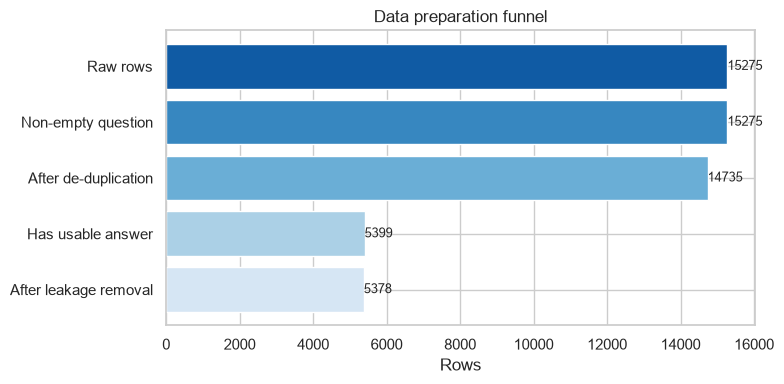

In [14]:
print(json.dumps(report, indent=2))
plots.plot_funnel(report); plt.show()

The funnel shows how many rows survive each step. From 15,275 raw rows I end up with 5,378 supervised examples: 3,783 for training, 541 for validation and 1,054 for testing. De-duplication removes 540 rows, and the answer filter removes most of the rest (mainly the unanswered consumer queries).

To avoid leakage I removed 16 near-duplicate training questions and 5 training rows whose answer was identical to a held-out answer. Without this step the model could get credit for memorising test answers.

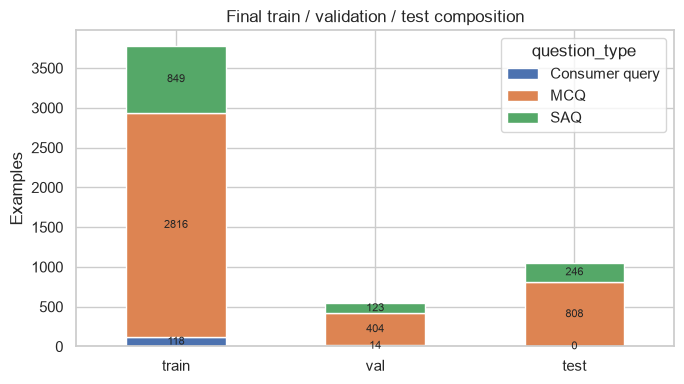

In [15]:
plots.plot_split_composition(sup); plt.show()

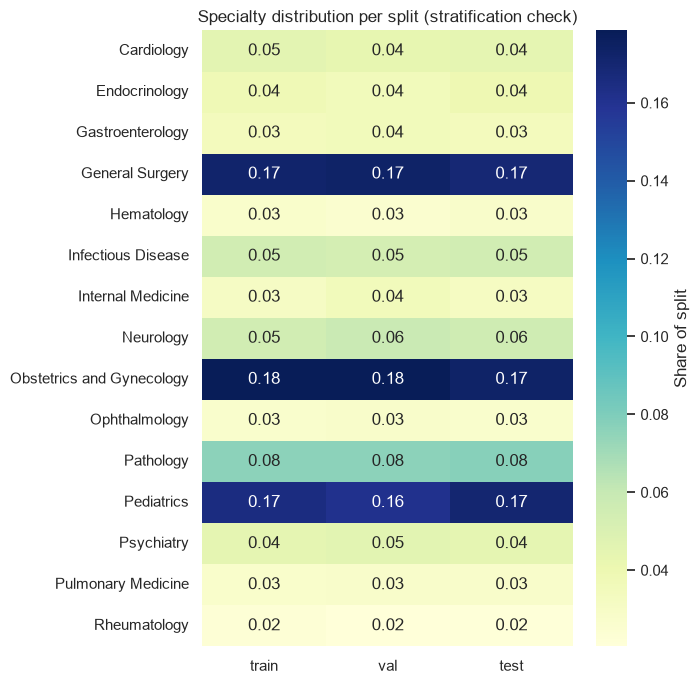

In [16]:
plots.plot_specialty_by_split(sup); plt.show()

The split plots confirm that train, validation and test have a similar mix of MCQs, SAQs and specialties, so the validation scores should be a fair guide to the test scores. The test split has no consumer queries because almost none of them have answers.

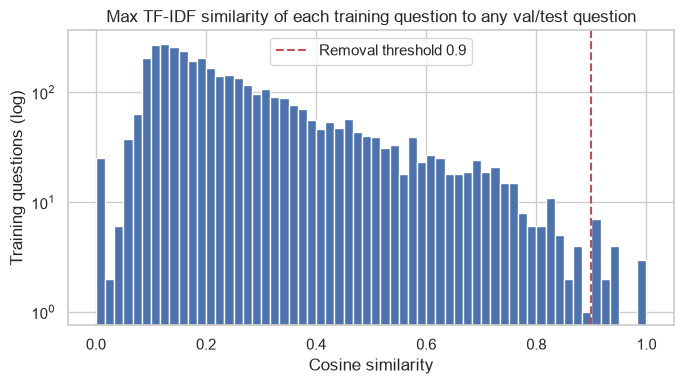

training questions with similarity >= 0.9 to a held-out question (removed): 16


In [17]:
from afrimed.config import PROCESSED_DIR
sims = np.load(PROCESSED_DIR / "train_max_sim_to_heldout.npy")
plots.plot_leakage(sims); plt.show()
print(f"training questions with similarity >= 0.9 to a held-out question (removed): {(sims >= 0.9).sum()}")

This histogram shows, for every training question, its highest TF-IDF similarity to any validation or test question. Most training questions are far from the held-out questions. The 16 training questions with similarity of 0.9 or more were removed, so the test set measures generalisation rather than memorisation.

## 7. Vocabulary and token lengths

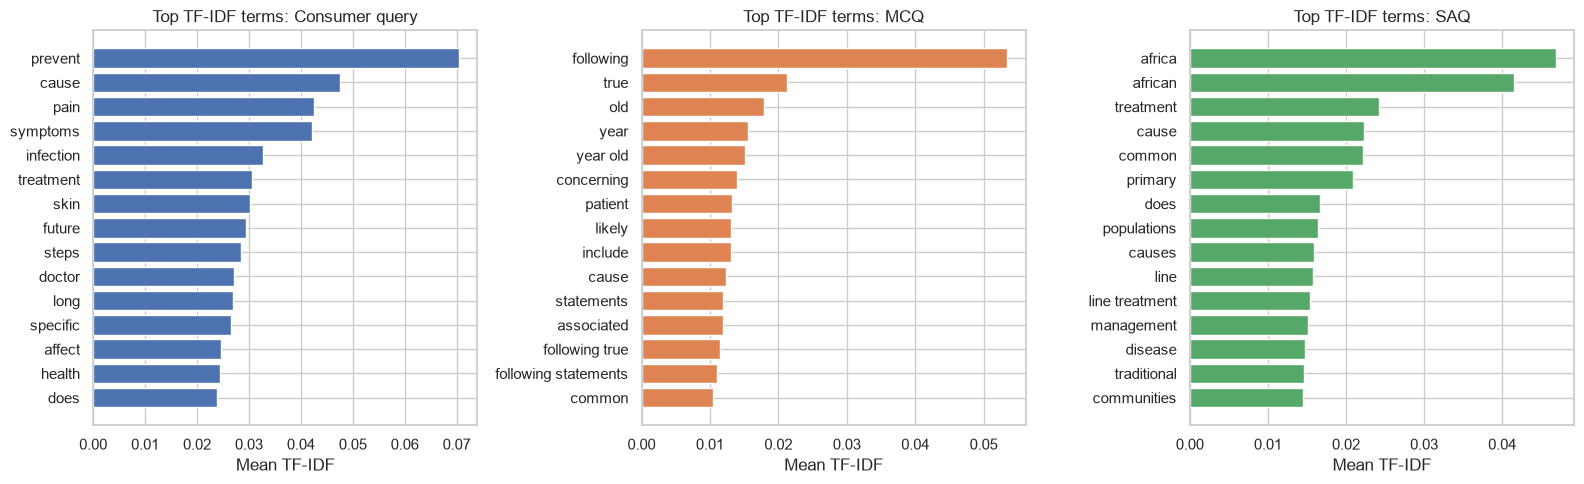

In [18]:
plots.plot_top_terms(sup); plt.show()

/Users/james/afrimed-assistant/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


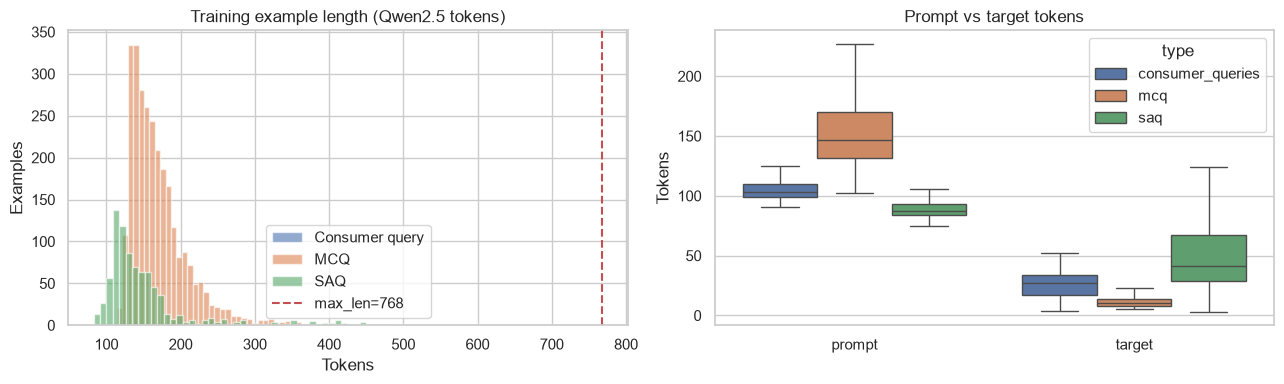

type          consumer_queries     mcq    saq
prompt count             118.0  2816.0  849.0
       mean              105.0   156.0   90.0
       std                 8.0    32.0   13.0
       min                91.0   102.0   75.0
       50%               103.0   147.0   87.0
       95%               120.0   220.0  107.0
       99%               124.0   264.0  154.0
       max               125.0   380.0  198.0
target count             118.0  2816.0  849.0
       mean               25.0    14.0   65.0
       std                11.0    18.0   70.0
       min                 4.0     5.0    3.0
       50%                27.0    10.0   41.0
       95%                41.0    36.0  246.0
       99%                49.0   101.0  366.0
       max                52.0   259.0  421.0
total  count             118.0  2816.0  849.0
       mean              130.0   170.0  155.0
       std                13.0    41.0   72.0
       min               102.0   107.0   83.0
       50%               130.0   160.0  133.0
       95%               152.0   247.0  345.0
       99%               161.0   322.0  452.0
       max               164.0   471.0  510.0

examples longer than 768 tokens: 0 / 3783


In [19]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
lengths = plots.plot_token_lengths(sup, tok); plt.show()
display(lengths.groupby("type")[["prompt", "target", "total"]].describe(percentiles=[0.5, 0.95, 0.99]).round(0).T)
print(f"examples longer than 768 tokens: {(lengths.total > 768).sum()} / {len(lengths)}")

I tokenize the full training examples (prompt plus answer) with the Qwen tokenizer. MCQ prompts are the longest because they include five options, and SAQ answers vary the most in length. No training example is longer than 768 tokens, so I use `max_len = 768` and do not have to drop or cut any data.

## 8. Example formatted training instance

This is exactly what the model sees during fine-tuning. Each example uses Qwen's chat template: a system message that defines the assistant, the user's question (with options for MCQs), and the assistant's answer. MCQ answers start with "Answer:" and the letter, followed by a short explanation.

During training I compute the loss only on the assistant's answer: the prompt tokens get the label -100, so the model is not trained to repeat the question.

In [20]:
from afrimed.prompts import build_prompt, format_user, format_target
from afrimed.data import load_split
train = load_split("train")
for qtype in ["mcq", "saq", "consumer_queries"]:
    r = train[train.question_type == qtype].iloc[0].to_dict()
    print("=" * 30, qtype, "=" * 30)
    print(build_prompt(tok, "causal", format_user(r)) + format_target(r))

============================== mcq ==============================
<|im_start|>system
You are AfriMed Assistant, a medical question-answering assistant focused on healthcare in African settings. Give accurate, concise, evidence-based answers. For multiple-choice questions, begin with 'Answer:' followed by the letter(s) of the correct option(s), then explain briefly.<|im_end|>
<|im_start|>user
Question: Which of the following conditions is characterized by an abnormal enlargement of the thyroid gland, often resulting in a visibly enlarged neck, and is endemic in certain regions of Africa due to dietary iodine deficiency?

Options:
A. Hashimoto's thyroiditis
B. Graves' disease
C. Toxic multinodular goiter
D. Simple (nontoxic) goiter
E. Thyroid cancer

Select the correct option(s).<|im_end|>
<|im_start|>assistant
Answer: D. Simple (nontoxic) goiter
Explanation: Simple (nontoxic) goiter is characterized by thyroid enlargement without associated thyroid dysfunction. It often results from iod

============================== saq ==============================
<|im_start|>system
You are AfriMed Assistant, a medical question-answering assistant focused on healthcare in African settings. Give accurate, concise, evidence-based answers. For multiple-choice questions, begin with 'Answer:' followed by the letter(s) of the correct option(s), then explain briefly.<|im_end|>
<|im_start|>user
Question: Which mosquito-borne disease is a leading cause of death in Africa?<|im_end|>
<|im_start|>assistant
Malaria, caused by the Plasmodium parasite, is a leading cause of death in Africa.
============================== consumer_queries ==============================
<|im_start|>system
You are AfriMed Assistant, a medical question-answering assistant focused on healthcare in African settings. Give accurate, concise, evidence-based answers. For multiple-choice questions, begin with 'Answer:' followed by the letter(s) of the correct option(s), then explain briefly.<|im_end|>
<|im_start|>user
Scen

**Summary.** After cleaning I have 5,378 supervised examples and 9,329 unanswered consumer queries for the domain gate. The main data challenges are:

* missing answers for almost all consumer queries,
* very short crowdsourced answers,
* answer-position bias in the MCQs,
* imbalance across countries and specialties,
* an official split that was not built for training.

Each of these is either handled in my pipeline or measured in the evaluation notebooks.